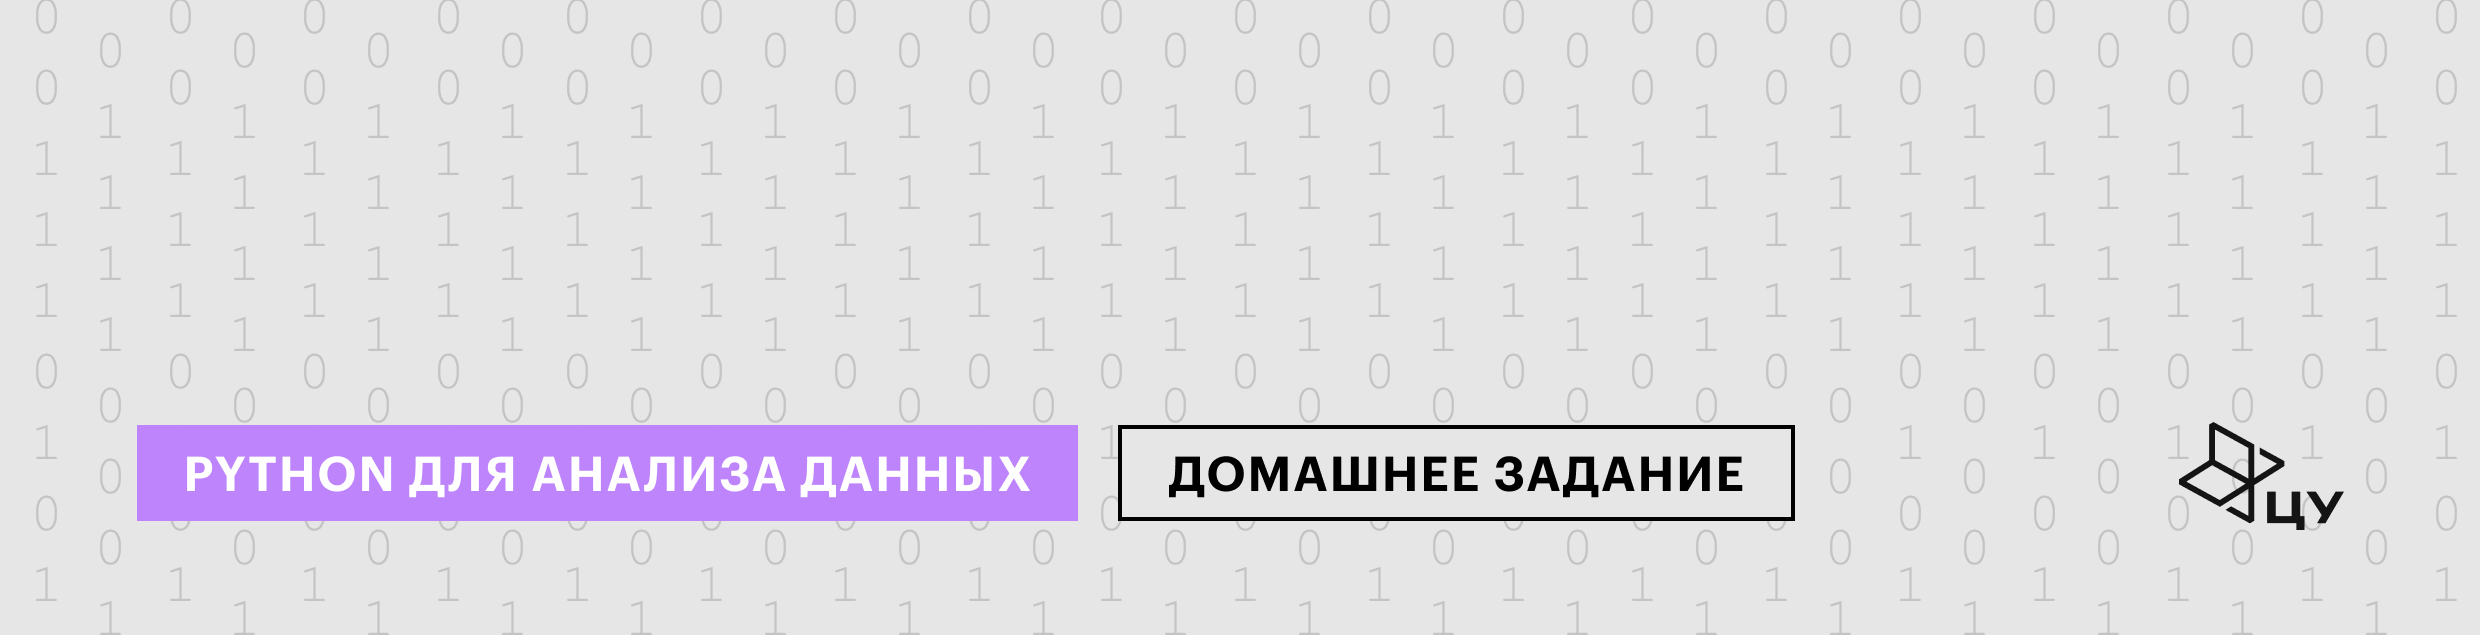

# Домашнее задание

## Неделя 9. NumPy-2: связь с pandas


Проблема: в логах просмотров есть некорректные длительности, а расчёты в массивах легко теряют связь с пользователями и фильмами.

Цель: подготовить проверенную витрину просмотров и пользователей, а затем средствами NumPy рассчитать выручку и прибыль при трёх вариантах стоимости подписки (249, 299 и 349 рублей) и вернуть результаты в pandas.

## Схема данных


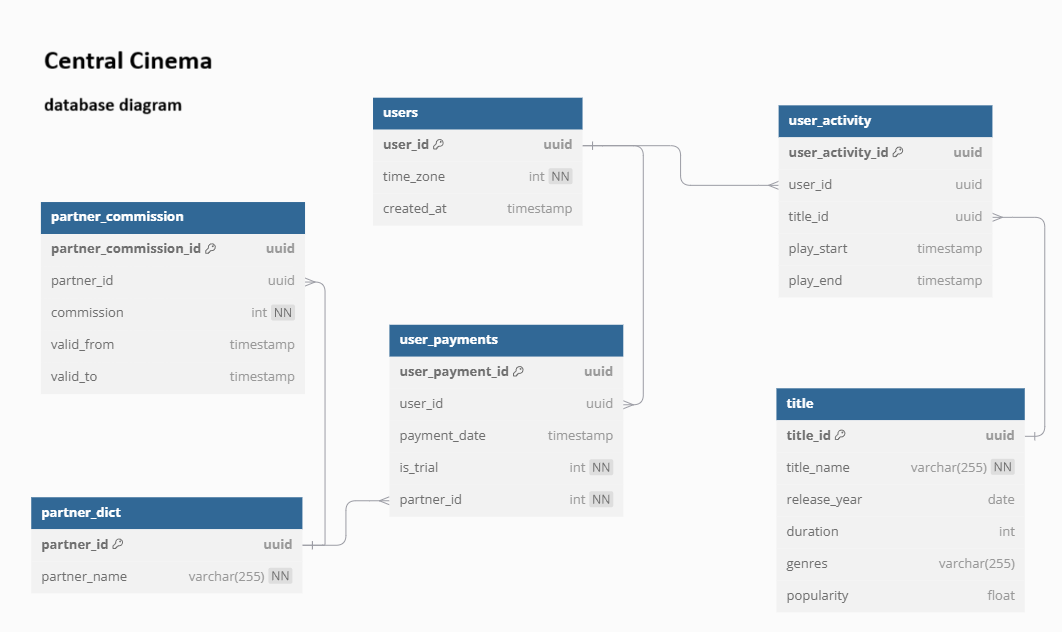


## Подготовка окружения и загрузка данных

Выполни эти ячейки без изменений. Если нужно, поменяй только `DATA_DIR`.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 130)
print('NumPy:', np.__version__, '| pandas:', pd.__version__)


NumPy: 2.5.4 | pandas: 3.0.6


In [2]:
DATA_DIR = None  # Если CSV лежат в другом месте, укажи путь, например Path('my_folder/data_set')

required_files = ['users.csv', 'user_activity.csv', 'user_payments.csv', 'title.csv']
if DATA_DIR is None:
    # Ищем папку data_set рядом с ноутбуком, уровнем выше и во вложенных папках
    candidates = [Path('data_set'), Path('../data_set'), *sorted(Path('.').glob('*/data_set'))]
    DATA_DIR = next((p for p in candidates
                     if all((p / name).is_file() for name in required_files)), None)

if DATA_DIR is None:
    raise FileNotFoundError(
        'Не найдены CSV. Распакуй весь комплект и укажи DATA_DIR в этой ячейке.'
    )
DATA_DIR = Path(DATA_DIR)
missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(f'В DATA_DIR отсутствуют: {missing_files}')

users = pd.read_csv(DATA_DIR / 'users.csv', parse_dates=['created_at'])
user_activity = pd.read_csv(
    DATA_DIR / 'user_activity.csv', parse_dates=['play_start', 'play_end']
)
user_payments = pd.read_csv(DATA_DIR / 'user_payments.csv', parse_dates=['payment_date'])
title_raw = pd.read_csv(DATA_DIR / 'title.csv', parse_dates=['release_date'])

assert users['user_id'].is_unique
assert user_activity['user_activity_id'].is_unique
assert user_payments['user_payment_id'].is_unique
assert user_activity['user_id'].isin(users['user_id']).all()
assert user_activity['title_id'].isin(title_raw['title_id']).all()
assert user_payments['user_id'].isin(users['user_id']).all()
assert set(user_payments['is_trial'].unique()).issubset({0, 1})

data_overview = pd.DataFrame({
    'rows': [len(users), len(user_activity), len(user_payments), len(title_raw)],
    'columns': [users.shape[1], user_activity.shape[1], user_payments.shape[1], title_raw.shape[1]],
    'missing': [df.isna().sum().sum()
                for df in [users, user_activity, user_payments, title_raw]]
}, index=['users', 'user_activity', 'user_payments', 'title_raw'])
data_overview

,rows,columns,missing
users,48868,3,0
user_activity,429338,5,0
user_payments,149896,5,0
title_raw,24766,6,0


## Задача 1 (1 балл)
Подготовь `title` из `title_raw`: удали только полные дубликаты, затем проверь уникальность `title_id`. Если после удаления полных дубликатов остались повторные ключи, расчёт нужно остановить.

Создай `sessions` левым соединением `user_activity` с полями `title_id`, `title_name`, `duration` из `title`. Используй `validate='many_to_one'`, сохрани число сессий и сделай `user_activity_id` индексом. Рассчитай `watch_minutes_raw = (play_end - play_start).dt.total_seconds() / 60`.

Из столбцов в порядке `watch_minutes_raw`, `duration` создай вещественный массив `session_values` через `to_numpy(dtype=float)` и сделай его независимой копией через `.copy()`. Названия и индекс должны остаться в `sessions`, вычисления следующих задач будут идти в NumPy.

In [3]:
# Твой код здесь

title = title_raw.drop_duplicates().copy()
assert title['title_id'].is_unique

sessions = user_activity.merge(
    title[['title_id', 'title_name', 'duration']],
    on='title_id', how='left', validate='many_to_one'
)
assert len(sessions) == len(user_activity)
sessions = sessions.set_index('user_activity_id')
sessions['watch_minutes_raw'] = (
    sessions['play_end'] - sessions['play_start']
).dt.total_seconds() / 60

session_values = sessions[['watch_minutes_raw', 'duration']].to_numpy(dtype=float).copy()
sessions.head()


,user_id,title_id,play_start,play_end,title_name,duration,watch_minutes_raw
user_activity_id,,,,,,,
43a06341ddde4d668548604a426ba079,88e277bd088040d28274104c21185fa8,98876206796e42cf84f986b72b4b87dc,2024-12-08 13:03:20,2024-12-08 13:20:20,Black,20,17.00
36f87483ef5b423ea185fcd66a1aad35,4968d96a9cf74478ba4bf2822afa047d,3e5a4d08e7db4744b1d1ca3597438c10,2025-04-07 17:20:21,2025-04-07 17:24:36,Try For You,5,4.25
ef401207d68149a19c508f18bed22f8b,366992810a4942e1ae275533481db7d9,15b762134b7148298b33ec345adc8d3e,2025-09-16 21:52:17,2025-09-16 22:05:47,Laws of the Game,18,13.50
bbe177cb386a4f5cb0f15c386487398c,aa200a8e4130461b9b2e40f19f754b15,697471a0a0ca43cea369e4e66a6d421a,2025-07-02 21:06:13,2025-07-02 21:06:13,Poulidor 1er,0,0.00
ec0ff228d50c42ca9ae5ec66f448764c,c68e59cf69ef407b8866033d26505989,697471a0a0ca43cea369e4e66a6d421a,2025-10-28 23:43:43,2025-10-28 23:43:43,Poulidor 1er,0,0.00


## Задача 2 (2 балла)

Используй столбцы `session_values`, без построчных циклов и `apply`.

1. `watch_valid`: длительность просмотра лежит в интервале (0; 1440] минут. `title_valid`: длительность фильма строго больше нуля. Верхнюю границу для фильма здесь не вводим.
2. `session_quality` через `np.select`: `invalid_title`, если некорректна длительность фильма; иначе `invalid_watch`, если некорректен просмотр; иначе `valid`. Первое правило имеет приоритет: сессия, у которой некорректны и фильм, и просмотр, относится к `invalid_title`.
3. `watch_minutes_clean` через `np.where`: исходные минуты при `watch_valid`, иначе `NaN`. Для суммарного времени просмотра некорректная длительность фильма не мешает учитывать корректную сессию.
4. `completion_raw`: минуты просмотра / длительность фильма только при выполнении обеих масок, иначе `NaN`. Чтобы не делить на ноль, сначала замени некорректные длительности фильма на `NaN` через `np.where`: деление на `NaN` даёт `NaN` без ошибок и предупреждений. Затем `completion = np.clip(completion_raw, 0, 1)` - страховка от просмотров длиннее фильма.
5. Добавь в `sessions` столбцы `watch_valid`, `title_valid`, `session_quality`, `watch_minutes_clean`, `completion_raw`, `completion` в исходном порядке строк.

In [4]:
# Твой код здесь

watch_minutes = session_values[:, 0]
duration = session_values[:, 1]

watch_valid = (watch_minutes > 0) & (watch_minutes <= 1440)
title_valid = duration > 0
session_quality = np.select(
    [~title_valid, ~watch_valid],
    ['invalid_title', 'invalid_watch'], default='valid'
)
watch_minutes_clean = np.where(watch_valid, watch_minutes, np.nan)
safe_duration = np.where(title_valid, duration, np.nan)
completion_raw = np.where(
    watch_valid & title_valid, watch_minutes / safe_duration, np.nan
)
completion = np.clip(completion_raw, 0, 1)

sessions['watch_valid'] = watch_valid
sessions['title_valid'] = title_valid
sessions['session_quality'] = session_quality
sessions['watch_minutes_clean'] = watch_minutes_clean
sessions['completion_raw'] = completion_raw
sessions['completion'] = completion
sessions.head()


,user_id,title_id,play_start,play_end,title_name,duration,...,watch_valid,title_valid,session_quality,watch_minutes_clean,completion_raw,completion
user_activity_id,,,,,,,,,,,,,
43a06341ddde4d668548604a426ba079,88e277bd088040d28274104c21185fa8,98876206796e42cf84f986b72b4b87dc,2024-12-08 13:03:20,2024-12-08 13:20:20,Black,20,...,True,True,valid,17.00,0.85,0.85
36f87483ef5b423ea185fcd66a1aad35,4968d96a9cf74478ba4bf2822afa047d,3e5a4d08e7db4744b1d1ca3597438c10,2025-04-07 17:20:21,2025-04-07 17:24:36,Try For You,5,...,True,True,valid,4.25,0.85,0.85
ef401207d68149a19c508f18bed22f8b,366992810a4942e1ae275533481db7d9,15b762134b7148298b33ec345adc8d3e,2025-09-16 21:52:17,2025-09-16 22:05:47,Laws of the Game,18,...,True,True,valid,13.50,0.75,0.75
bbe177cb386a4f5cb0f15c386487398c,aa200a8e4130461b9b2e40f19f754b15,697471a0a0ca43cea369e4e66a6d421a,2025-07-02 21:06:13,2025-07-02 21:06:13,Poulidor 1er,0,...,False,False,invalid_title,NaN,NaN,NaN
ec0ff228d50c42ca9ae5ec66f448764c,c68e59cf69ef407b8866033d26505989,697471a0a0ca43cea369e4e66a6d421a,2025-10-28 23:43:43,2025-10-28 23:43:43,Poulidor 1er,0,...,False,False,invalid_title,NaN,NaN,NaN


## Задача 3 (1 балл)

Создай `completion_segment` через `np.select` и добавь в `sessions`:

| Условие | Сегмент |
|---|---|
| `completion` неизвестна | `unknown` |
| `0 <= completion < 0.8` | `partial` |
| `0.8 <= completion < 0.9` | `mostly_complete` |
| `0.9 <= completion <= 1` | `near_complete` |

Значения ровно `0.8` относятся к `mostly_complete`, ровно `0.9` - к `near_complete`. Построй `segment_report` с числом сессий и долей от всех сессий для каждого сегмента. Не исключай `unknown` из знаменателя.

In [5]:
# Твой код здесь

completion_segment = np.select(
    [np.isnan(completion),
     (completion >= 0) & (completion < 0.8),
     (completion >= 0.8) & (completion < 0.9),
     (completion >= 0.9) & (completion <= 1)],
    ['unknown', 'partial', 'mostly_complete', 'near_complete'],
    default='unknown'
)
sessions['completion_segment'] = completion_segment
segment_report = sessions['completion_segment'].value_counts().reindex(
    ['unknown', 'partial', 'mostly_complete', 'near_complete'], fill_value=0
).to_frame('sessions')
segment_report['share'] = segment_report['sessions'] / len(sessions)
segment_report


,sessions,share
completion_segment,,
unknown,56312,0.131160
partial,75868,0.176709
mostly_complete,126699,0.295103
near_complete,170459,0.397028


## Задача 4 (1.5 балла)

Создай `user_report` для всех пользователей из `users`, включая тех, у кого нет корректных просмотров. Индекс - `user_id`, отсортированный по возрастанию. Одна строка - один пользователь.

Агрегируй в pandas следующие столбцы:

- `valid_sessions` - число сессий с `watch_valid = True`;
- `total_watch_minutes` - сумма `watch_minutes_clean`;
- `ratio_sessions` - число известных `completion`;
- `near_complete_sessions` - число сессий сегмента `near_complete`.

Для отсутствующих агрегатов числа и сумму заполни нулём. В NumPy рассчитай `avg_session_minutes = total_watch_minutes / valid_sessions` и `near_complete_rate = near_complete_sessions / ratio_sessions`. При нулевом знаменателе оставь `NaN`: как и в задаче 2, замени нули в знаменателе на `NaN` через `np.where`.

Верни результаты в `user_report` как `pd.Series(..., index=user_report.index)`. Покажи правильность выравнивания: создай копию таблицы в обратном порядке строк и присвой ей эту же Series среднего времени; значения по каждому `user_id` должны сохраниться.

In [6]:
# Твой код здесь

user_stats = sessions.assign(
    near_complete=sessions['completion_segment'].eq('near_complete')
).groupby('user_id').agg(
    valid_sessions=('watch_valid', 'sum'),
    total_watch_minutes=('watch_minutes_clean', 'sum'),
    ratio_sessions=('completion', 'count'),
    near_complete_sessions=('near_complete', 'sum')
)
user_report = user_stats.reindex(users['user_id']).fillna(0).sort_index()
count_columns = ['valid_sessions', 'ratio_sessions', 'near_complete_sessions']
user_report[count_columns] = user_report[count_columns].astype(int)

valid_counts = user_report['valid_sessions'].to_numpy()
ratio_counts = user_report['ratio_sessions'].to_numpy()
avg_session_minutes = user_report['total_watch_minutes'].to_numpy() / np.where(
    valid_counts > 0, valid_counts, np.nan
)
near_complete_rate = user_report['near_complete_sessions'].to_numpy() / np.where(
    ratio_counts > 0, ratio_counts, np.nan
)
avg_series = pd.Series(avg_session_minutes, index=user_report.index)
user_report['avg_session_minutes'] = avg_series
user_report['near_complete_rate'] = pd.Series(near_complete_rate, index=user_report.index)

reversed_report = user_report.iloc[::-1].copy()
reversed_report['avg_session_minutes'] = avg_series
pd.testing.assert_series_equal(
    reversed_report['avg_session_minutes'].sort_index(),
    user_report['avg_session_minutes']
)
user_report.head()


,valid_sessions,total_watch_minutes,ratio_sessions,near_complete_sessions,avg_session_minutes,near_complete_rate
user_id,,,,,,
0002c34fd14b40c8a2bf12b51ce99698,0,0.00,0,0,NaN,NaN
0007baa2fd994e5ca77e1cc97af969b7,0,0.00,0,0,NaN,NaN
000a42221c7046e986da8fe0c323088a,25,1558.26,25,15,62.3304,0.6
000adc8022634e18bf4c36e0a5245055,0,0.00,0,0,NaN,NaN
000b61e0bfff4222bc8d8825e8000b06,0,0.00,0,0,NaN,NaN


## Задача 5 (1 балл)

Для сравнения пользователей подготовь `feature_frame` из трёх столбцов `user_report` в порядке: `valid_sessions`, `total_watch_minutes`, `avg_session_minutes`.

Преобразуй его в вещественную матрицу `features`. Рассчитай для каждого столбца среднее `means` через `np.nanmean` и стандартное отклонение `stds` через `np.nanstd`, с `axis=0, keepdims=True`. Стандартизация - это перевод в общую шкалу: `z = (x - mean) / std`.

Через broadcasting получи `z_values`. Исходные `NaN` должны остаться `NaN`. Верни результат в `z_features` с исходным индексом и названиями `z_valid_sessions`, `z_total_watch_minutes`, `z_avg_session_minutes`.

In [7]:
# Твой код здесь

feature_frame = user_report[
    ['valid_sessions', 'total_watch_minutes', 'avg_session_minutes']
]
features = feature_frame.to_numpy(dtype=float)
means = np.nanmean(features, axis=0, keepdims=True)
stds = np.nanstd(features, axis=0, keepdims=True)
z_values = (features - means) / stds
z_features = pd.DataFrame(
    z_values, index=feature_frame.index,
    columns=['z_valid_sessions', 'z_total_watch_minutes', 'z_avg_session_minutes']
)
z_features.head()


,z_valid_sessions,z_total_watch_minutes,z_avg_session_minutes
user_id,,,
0002c34fd14b40c8a2bf12b51ce99698,-0.661252,-0.640975,NaN
0007baa2fd994e5ca77e1cc97af969b7,-0.661252,-0.640975,NaN
000a42221c7046e986da8fe0c323088a,1.504418,1.337795,-0.042795
000adc8022634e18bf4c36e0a5245055,-0.661252,-0.640975,NaN
000b61e0bfff4222bc8d8825e8000b06,-0.661252,-0.640975,NaN


## Задача 6 (0.5 балла)

Через `np.argsort` выбери 10 пользователей с максимальным `total_watch_minutes`. `np.argsort` сортирует по возрастанию, поэтому сортируй отрицательные значения.

Позиции массива примени к `user_report` через `.iloc`, получив `top_users`. Покажи `valid_sessions`, `total_watch_minutes`, `avg_session_minutes`.

In [8]:
# Твой код здесь

top_positions = np.argsort(-user_report['total_watch_minutes'].to_numpy())[:10]
top_users = user_report.iloc[top_positions][
    ['valid_sessions', 'total_watch_minutes', 'avg_session_minutes']
]
top_users


,valid_sessions,total_watch_minutes,avg_session_minutes
user_id,,,
fcf7f0cc13984b91889f7bf0966af708,83,5826.87,70.203253
ec0f08fdaf154af99d1b3ce2b34af314,76,5800.78,76.326053
be24262ef8144a27b052687796db3c27,79,5786.21,73.243165
29ddb5292b9a4bf58dace022fa545884,89,5729.72,64.378876
c2fe8ab10f674291b59a784fb8fe9bb5,85,5712.49,67.205765
f8e642d3fc5e4eb78423165d1e321608,74,5644.06,76.271081
2f15c6d7cb4745e98d6c1bba7e36e034,72,5562.75,77.260417
d53b2639801a43179b30231a28584176,77,5436.21,70.600130
52c9a19d8ec1465685b503aa073c8d3f,71,5332.73,75.108873


## Задача 7 (2 балла)

Сейчас месячная подписка стоит 299 рублей. Финансовый отдел хочет сравнить её с вариантами 249 и 349 рублей. В расчётах считаем число операций неизменным, эквайринг - 3% от выручки, фиксированные расходы - 300 000 рублей каждый месяц. Комиссию привлечения партнёров из прошлых ДЗ здесь не учитываем.

1. Создай `paid_counts`: число строк с `is_trial == 0` по месяцу `payment_date` (`dt.to_period('M')`). Месяцы, в которых были только пробные операции, должны остаться в результате с нулём, поэтому группируй все операции, а не только платные. Количество операций не заменяй числом уникальных пользователей.
2. Создай `prices = np.array([249., 299., 349.])`. Broadcasting должен дать `gross_values` формы `(n_months, 3)` без циклов по месяцам и ценам: преврати `paid_counts` в столбец формы `(n_months, 1)`.
3. `profit_values = gross_values * (1 - 0.03) - 300_000`. Верни `monthly_revenue` и `monthly_profit` в DataFrame с индексом `paid_counts.index`, столбцами `prices` и именем оси столбцов `price_rub`.
4. По `axis=0` создай `scenario_summary`: `total_revenue`, `total_profit`, `mean_monthly_profit`, `profitable_months` (месяцев с прибылью строго > 0). Индекс - цена.

In [9]:
# Твой код здесь

paid_counts = user_payments['is_trial'].eq(0).groupby(
    user_payments['payment_date'].dt.to_period('M')
).sum()
prices = np.array([249., 299., 349.])
gross_values = paid_counts.to_numpy()[:, None] * prices
profit_values = gross_values * (1 - 0.03) - 300_000

monthly_revenue = pd.DataFrame(gross_values, index=paid_counts.index, columns=prices)
monthly_profit = pd.DataFrame(profit_values, index=paid_counts.index, columns=prices)
monthly_revenue.columns.name = 'price_rub'
monthly_profit.columns.name = 'price_rub'

scenario_summary = pd.DataFrame({
    'total_revenue': gross_values.sum(axis=0),
    'total_profit': profit_values.sum(axis=0),
    'mean_monthly_profit': profit_values.mean(axis=0),
    'profitable_months': (profit_values > 0).sum(axis=0)
}, index=pd.Index(prices, name='price_rub'))
scenario_summary


,total_revenue,total_profit,mean_monthly_profit,profitable_months
price_rub,,,,
249.0,25155972.0,19601292.84,1.225081e+06,15
299.0,30207372.0,24501150.84,1.531322e+06,15
349.0,35258772.0,29401008.84,1.837563e+06,15


## Задача 8 (1 балл)

Сформулируй 4-6 предложений по результатам. Подкрепи каждое численное утверждение расчётом:

1. Сколько сессий имеют некорректное время просмотра и какова их доля от всех сессий? Сколько из них приходится на фильмы с некорректной длительностью? Не складывай пересекающиеся маски. Что это говорит об источнике ошибок?
2. Сколько пользователей не имеют ни одной корректной сессии? Почему их среднее время - `NaN`, а суммарное время - 0?
3. Какова доля `near_complete` среди сессий с известным `completion`? Чем она отличается от доли в `segment_report`?
4. Какова суммарная учебная прибыль при каждой из трёх цен? Назови минимум два ограничения такого расчёта, в том числе неизменность спроса.

In [10]:
# Твой код здесь

invalid_watch_count = (~watch_valid).sum()
invalid_watch_share = invalid_watch_count / len(sessions)
invalid_both_count = (~watch_valid & ~title_valid).sum()
users_without_valid = user_report['valid_sessions'].eq(0).sum()
known_completion_count = sessions['completion'].notna().sum()
near_complete_count = sessions['completion_segment'].eq('near_complete').sum()
near_complete_known_share = near_complete_count / known_completion_count
near_complete_all_share = segment_report.loc['near_complete', 'share']

print('Некорректное время просмотра:', invalid_watch_count)
print(f'Доля таких сессий: {invalid_watch_share:.2%}')
print('Из них с некорректной длительностью фильма:', invalid_both_count)
print('Пользователей без корректных сессий:', users_without_valid)
print('Сессий near_complete:', near_complete_count)
print('Сессий с известным completion:', known_completion_count)
print(f'Доля near_complete среди известных: {near_complete_known_share:.2%}')
print(f'Доля near_complete среди всех: {near_complete_all_share:.2%}')
scenario_summary[['total_profit']]


Некорректное время просмотра: 56312
Доля таких сессий: 13.12%
Из них с некорректной длительностью фильма: 56116
Пользователей без корректных сессий: 25377
Сессий near_complete: 170459
Сессий с известным completion: 373026
Доля near_complete среди известных: 45.70%
Доля near_complete среди всех: 39.70%


,total_profit
price_rub,
249.0,19601292.84
299.0,24501150.84
349.0,29401008.84


**Вывод:**

Некорректное время просмотра есть у 56 312 сессий, это 13,12% всех сессий.
Из них 56 116 относятся к фильмам с некорректной длительностью: ошибки часто встречаются вместе, поэтому стоит проверить и логи просмотров, и справочник фильмов, хотя точную причину по этим данным определить нельзя.
У 25 377 пользователей нет корректных сессий: сумма времени у них равна 0, а среднее — NaN, потому что делить нужно на нулевое число сессий.
Доля near_complete среди сессий с известным completion равна 45,70%, а среди всех сессий — 39,70%, так как во втором случае в знаменатель входят и unknown.
Суммарная учебная прибыль при цене 249 рублей составляет 19 601 292,84 рубля, при 299 — 24 501 150,84 рубля, при 349 — 29 401 008,84 рубля.
В расчёте спрос и число оплат не меняются при изменении цены, а расходы ограничены эквайрингом и фиксированной суммой: например, налоги и комиссия партнёров не учтены, поэтому это сравнение сценариев, а не прогноз реальной прибыли.
